Device: cpu
1 {'reconstruction': 189.31, 'kl': 6.57}
2 {'reconstruction': 165.5, 'kl': 5.34}
3 {'reconstruction': 160.08, 'kl': 5.41}
4 {'reconstruction': 157.21, 'kl': 5.47}
5 {'reconstruction': 155.31, 'kl': 5.52}


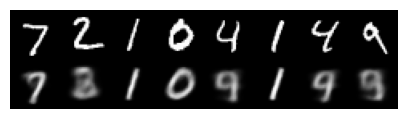

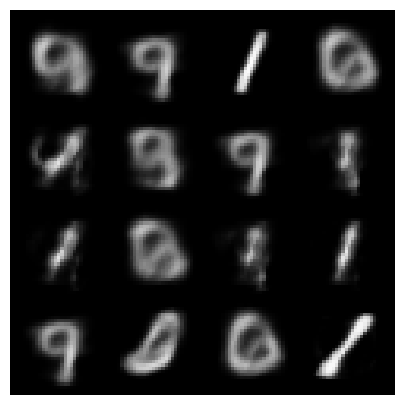

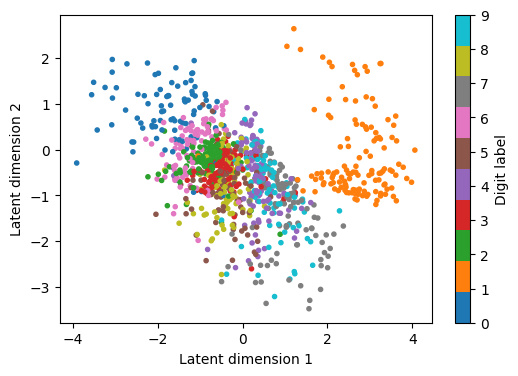

In [11]:
# Lab 1: Variational Autoencoder for Image Generation (MNIST)


# ---------------- Common Setup ----------------
from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out = Path("lab_outputs")
out.mkdir(exist_ok=True)
print("Device:", device)

# ---------------- Step 1: Load MNIST ----------------
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

train = datasets.MNIST("data", train=True, download=True,
                       transform=transforms.ToTensor())
test = datasets.MNIST("data", train=False, download=True,
                      transform=transforms.ToTensor())
loader = DataLoader(train, batch_size=128, shuffle=True)

# ---------------- Step 2: Build the VAE ----------------
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU())
        self.mean = nn.Linear(256, 2)
        self.logvar = nn.Linear(256, 2)
        self.decoder = nn.Sequential(nn.Linear(2, 256), nn.ReLU(),
                                     nn.Linear(256, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.encoder(x)
        return self.mean(h), self.logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decoder(z), mu, logvar

vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=0.001)

# ---------------- Step 3: Train (record both loss terms) ----------------
import torch.nn.functional as F

for epoch in range(1, 6):
    vae.train()
    totals = dict(reconstruction=0.0, kl=0.0)
    for x, _ in loader:
        x = x.to(device)
        generated, mu, logvar = vae(x)
        recon = F.binary_cross_entropy(generated, x.flatten(1), reduction="sum")
        kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum()
        loss = (recon + kl) / x.size(0)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        totals["reconstruction"] += recon.item()
        totals["kl"] += kl.item()
    print(epoch, {k: round(v / len(train), 2) for k, v in totals.items()})

torch.save(vae.state_dict(), out / "vae_mnist.pt")

# ---------------- Step 4: Generate samples + latent space ----------------
def show_grid(images, name, nrow=4):
    grid = make_grid(images.cpu(), nrow=nrow)
    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    plt.savefig(out / name, bbox_inches="tight")
    plt.show()

vae.eval()
with torch.no_grad():
    x, y = next(iter(DataLoader(test, batch_size=1024)))
    mu, _ = vae.encode(x.to(device))
    recon = vae.decoder(mu[:8]).reshape(-1, 1, 28, 28)
    samples = vae.decoder(torch.randn(16, 2, device=device))
    show_grid(torch.cat([x[:8], recon.cpu()]), "vae_reconstructed.png", nrow=8)
    show_grid(samples.reshape(-1, 1, 28, 28), "vae_generated.png")
    coords = mu.cpu()

plt.figure(figsize=(6, 4))
plt.scatter(coords[:, 0], coords[:, 1], c=y, cmap="tab10", s=9)
plt.colorbar(ticks=range(10), label="Digit label")
plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.savefig(out / "vae_latent.png", bbox_inches="tight")
plt.show()